In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np

# GPU kullanılabiliyor mu kontrol edelim
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Kullanılan cihaz: {device}")

ModuleNotFoundError: No module named 'torch'

Variational Autoencoder (VAE) ile Görüntü Üretimi - MNIST Projesi
Bu projede, derin öğrenme tekniklerinden biri olan Variational Autoencoder (VAE) mimarisini kullanarak el yazısı rakamlardan (MNIST veri seti) yeni görüntüler üretmeyi hedefliyorum. Proje; veri ön işleme, model inşası, eğitim ve sonuçların görselleştirilmesi aşamalarından oluşmaktadır

In [ ]:
# Veri dönüştürme: Görüntüleri 0-1 arasına çekiyoruz (BCE kaybı için gerekli)
transform = transforms.Compose([
    transforms.ToTensor() # Görüntüyü 0-1 arasına normalize eder
])

# MNIST veri setini (60.000 görüntü) indiriyoruz
train_dataset = datasets.MNIST(root='./data', train=True, transform=transform, download=True)

# Verileri 128'lik paketler (batch) halinde yüklüyoruz
train_loader = DataLoader(dataset=train_dataset, batch_size=128, shuffle=True)

print(f"Toplam görüntü sayısı: {len(train_dataset)}")
print("Veri seti başarıyla hazırlandı.")

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 490kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.66MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.98MB/s]

Toplam görüntü sayısı: 60000
Veri seti başarıyla hazırlandı.


1. Veri Setinin Hazırlanması
Bu aşamada MNIST veri setini indiriyoruz. Görüntüleri modelin işleyebileceği Tensor formatına çevirip, eğitim sırasında verileri gruplar (batch) halinde çekebilmek için DataLoader yapısını kuruyoruz.

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim):
        super(VAE, self).__init__()

        # 1. Encoder (Kodlayıcı): Görüntüyü alır ve gizli uzay parametrelerini üretir
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, 400), # MNIST görüntüleri 28x28 pikseldir
            nn.ReLU()
        )
        # Ortalama (mu) ve Varyans (logvar) değerleri
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_logvar = nn.Linear(400, latent_dim)

        # 2. Decoder (Kod Çözücü): Gizli uzaydaki noktadan tekrar görüntü üretir
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 400),
            nn.ReLU(),
            nn.Linear(400, 28 * 28),
            nn.Sigmoid() # Çıktıları 0-1 arasına sıkıştırır (BCE kaybı için)
        )

    # Reparameterization Trick: Eğitimin devam edebilmesi için gürültü ekleme aşaması
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        # Görüntüyü düzleştir (flatten)
        x = x.view(-1, 28 * 28)

        # Encode aşaması
        h = self.encoder(x)
        mu, logvar = self.fc_mu(h), self.fc_logvar(h)

        # Örnekleme (Sampling)
        z = self.reparameterize(mu, logvar)

        # Decode aşaması
        return self.decoder(z), mu, logvar

# Gizli uzay boyutunu 2 seçtim, böylece gizli uzayı doğrudan iki eksende çizebiliyorum
latent_dim = 2
model = VAE(latent_dim).to(device)
print(f"VAE Modeli oluşturuldu. Gizli uzay boyutu: {latent_dim}")

VAE Modeli oluşturuldu. Gizli uzay boyutu: 2


2. Model Mimarisi: VAE (Variational Autoencoder)
Modelimiz iki ana parçadan oluşuyor:

Encoder (Kodlayıcı): Giriş görüntüsünü gizli bir uzaya (latent space) sıkıştırır.

Decoder (Kod Çözücü): Bu gizli uzaydaki noktalardan orijinal görüntüyü tekrar inşa eder.
Not: "Reparameterization Trick" kullanarak ağın türevlenebilir kalmasını sağlıyoruz.

In [ ]:
# Kayıp Fonksiyonu: ELBO (Evidence Lower Bound)
def loss_function(recon_x, x, mu, logvar):
    # 1. Yeniden Yapılandırma Kaybı (Görüntü benzerliği)
    BCE = nn.functional.binary_cross_entropy(recon_x, x.view(-1, 784), reduction='sum')

    # 2. KL Divergence (Gizli uzay düzeni)
    # Bu formül gizli uzayı standart normal dağılıma zorlar
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    # Toplam Kayıp
    return BCE + KLD

# Optimizer: Adam, öğrenme oranı 0.001
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# VAE için özel ELBO kaybını tanımlıyoruz: 
# Yeniden yapılandırma hatası (BCE) + Düzenlileştirme (KLD)

In [ ]:
epochs = 10 # Veri seti üzerinden kaç kez geçilecek
model.train() # Modeli eğitim moduna al

for epoch in range(epochs):
    train_loss = 0
    for batch_idx, (data, _) in enumerate(train_loader):
        data = data.to(device) # Veriyi GPU'ya gönder

        optimizer.zero_grad() # Gradyanları sıfırla

        # Modeli çalıştır
        recon_batch, mu, logvar = model(data)

        # Hatayı hesapla
        loss = loss_function(recon_batch, data, mu, logvar)

        # Geriye yayılım (Backpropagation) ve ağırlık güncelleme
        loss.backward()
        train_loss += loss.item()
        optimizer.step()

    print(f'Epoch {epoch+1} tamamlandı! Ortalama Kayıp: {train_loss / len(train_dataset):.4f}')

print("Eğitim bitti! Artık modelimiz görüntü üretmeye hazır.")

Epoch 1 tamamlandı! Ortalama Kayıp: 189.7733
Epoch 2 tamamlandı! Ortalama Kayıp: 167.1611
Epoch 3 tamamlandı! Ortalama Kayıp: 163.6833
Epoch 4 tamamlandı! Ortalama Kayıp: 161.2025
Epoch 5 tamamlandı! Ortalama Kayıp: 159.3088
Epoch 6 tamamlandı! Ortalama Kayıp: 157.8650
Epoch 7 tamamlandı! Ortalama Kayıp: 156.7769
Epoch 8 tamamlandı! Ortalama Kayıp: 155.7654
Epoch 9 tamamlandı! Ortalama Kayıp: 154.9906
Epoch 10 tamamlandı! Ortalama Kayıp: 154.2692
Eğitim bitti! Artık modelimiz görüntü üretmeye hazır.


## 3. Modelin Eğitilmesi
Modeli 10 epoch eğittim. Her epoch'ta eğitim verisi 128'lik batch'ler halinde modele veriliyor, kayıp hesaplanıyor ve ağırlıklar Adam ile güncelleniyor.

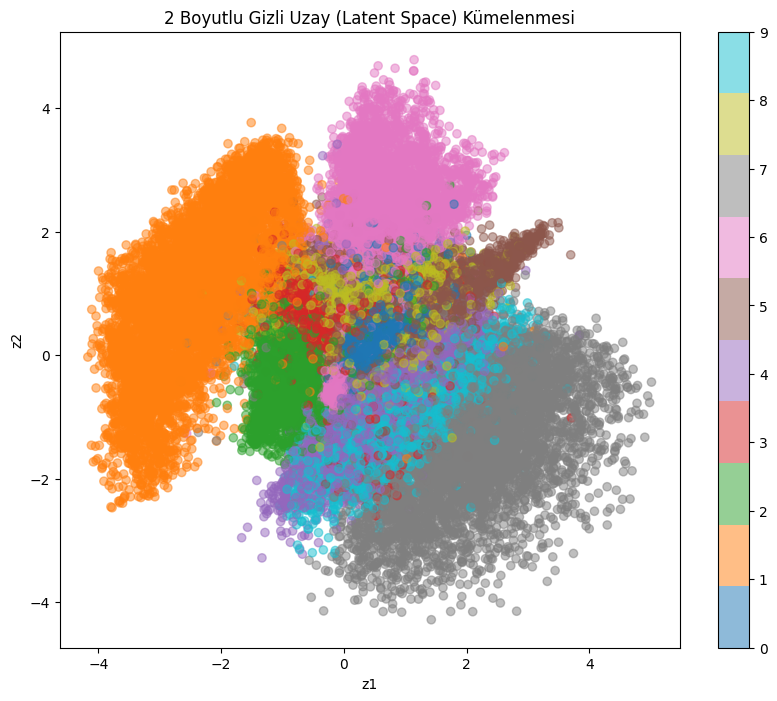

In [ ]:
def plot_latent_space(model, dataloader):
    model.eval()
    latents = []
    labels = []
    with torch.no_grad():
        for data, label in dataloader:
            data = data.to(device)
            _, mu, _ = model(data)
            latents.append(mu.cpu())
            labels.append(label)

    latents = torch.cat(latents, dim=0).numpy()
    labels = torch.cat(labels, dim=0).numpy()

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(latents[:, 0], latents[:, 1], c=labels, cmap='tab10', alpha=0.5)
    plt.colorbar(scatter)
    plt.title("2 Boyutlu Gizli Uzay (Latent Space) Kümelenmesi")
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.show()

plot_latent_space(model, train_loader)
plt.savefig('kumeleme_grafigi.png', dpi=300, bbox_inches='tight')

4. Sonuçlar ve Gizli Uzayda Gezinme
Eğitim tamamlandıktan sonra, modelin daha önce hiç görmediği rastgele noktalardan nasıl rakamlar ürettiğini test ediyoruz. Ayrıca iki rakam arasında "geçiş" (interpolation) yaparak gizli uzayın sürekliliğini gözlemliyoruz.

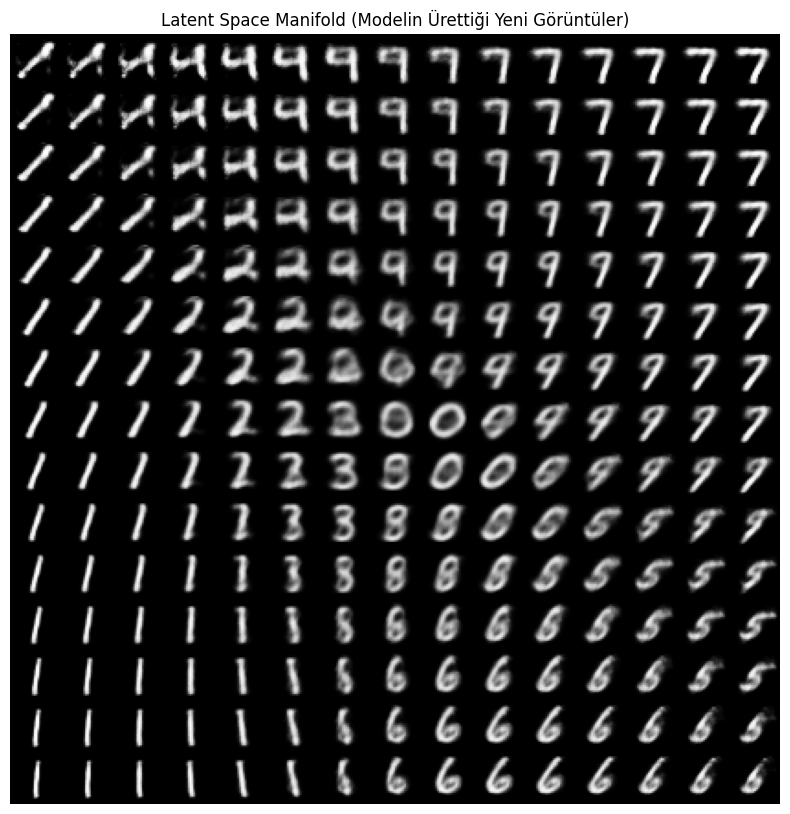

In [ ]:
def plot_reconstructed_manifold(model, n=15):
    # n x n boyutunda bir ızgara oluşturuyoruz
    digit_size = 28
    figure = np.zeros((digit_size * n, digit_size * n))

    # Gizli uzayda (z1, z2) koordinatlarını belirliyoruz
    grid_x = np.linspace(-3, 3, n)
    grid_y = np.linspace(-3, 3, n)

    model.eval()
    with torch.no_grad():
        for i, yi in enumerate(grid_y):
            for j, xi in enumerate(grid_x):
                z_sample = torch.tensor([[xi, yi]], dtype=torch.float).to(device)
                x_decoded = model.decoder(z_sample)
                digit = x_decoded.view(digit_size, digit_size).cpu().numpy()
                figure[i * digit_size: (i + 1) * digit_size,
                       j * digit_size: (j + 1) * digit_size] = digit

    plt.figure(figsize=(10, 10))
    plt.imshow(figure, cmap='Greys_r')
    plt.title("Latent Space Manifold (Modelin Ürettiği Yeni Görüntüler)")
    plt.axis('off')
    plt.savefig('manifold_cikisi.png', dpi=300, bbox_inches='tight')
    plt.show()


plot_reconstructed_manifold(model)

 Gizli Uzay Manifoldu (Latent Manifold)
Bu bölümde, modelin öğrendiği 2 boyutlu gizli uzayı bir ızgara şeklinde tarıyoruz. n x n boyutunda bir matris oluşturarak, gizli uzayın farklı noktalarından örnekler alıyor ve modelin bu noktalarda hangi rakamları "hayal ettiğini" görüyoruz. Bu görselleştirme, modelin benzer rakamları gizli uzayda birbirine yakın bölgelerde gruplayıp gruplamadığını anlamamızı sağlar.

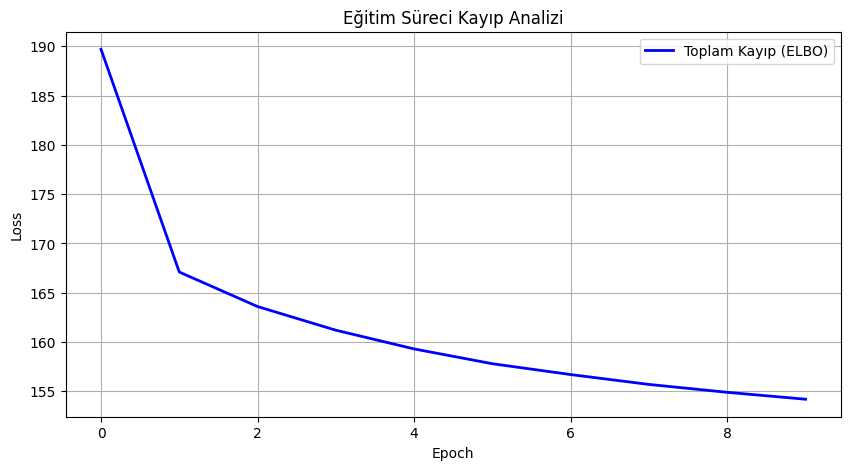

In [ ]:
# Eğitim döngüsünde kayıpları bir listeye kaydetmediğim için,
# epoch çıktılarında yazan ortalama kayıpları elle girdim (eğitim çıktısıyla aynı değerler).

history = [189.7, 167.1, 163.6, 161.2, 159.3, 157.8, 156.7, 155.7, 154.9, 154.2]
plt.figure(figsize=(10, 5))
plt.plot(history, label='Toplam Kayıp (ELBO)', color='blue', linewidth=2)
plt.title('Eğitim Süreci Kayıp Analizi')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Eğitim Analizi
Toplam kaybın (BCE + KL) epoch'lara göre nasıl değiştiğine bakıyorum. BCE ve KL terimlerini ayrı ayrı kaydetmedim, sadece toplam kayıp var.

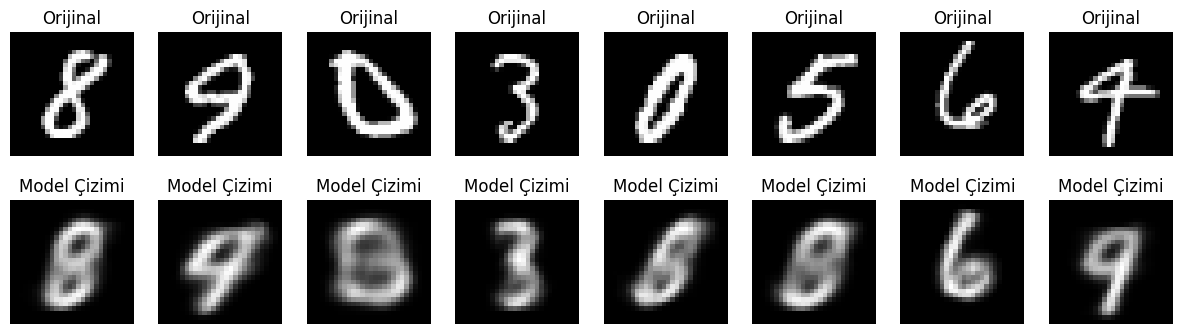

In [ ]:
def plot_reconstruction(model, dataloader, n=8):
    model.eval()
    with torch.no_grad():
        data, _ = next(iter(dataloader))
        data = data.to(device)
        recon, _, _ = model(data)

        data = data.cpu().numpy()
        recon = recon.cpu().numpy()

        plt.figure(figsize=(15, 4))
        for i in range(n):
            # Orijinal
            ax = plt.subplot(2, n, i + 1)
            plt.imshow(data[i][0], cmap='gray')
            plt.title("Orijinal")
            plt.axis('off')

            # Yeniden Yapılandırma
            ax = plt.subplot(2, n, i + 1 + n)
            plt.imshow(recon[i].reshape(28, 28), cmap='gray')
            plt.title("Model Çizimi")
            plt.axis('off')
        plt.show()

plot_reconstruction(model, train_loader)

## Yeniden Yapılandırma (Reconstruction) Kontrolü
Burada eğitim setinden bir batch alıp görüntüleri encoder ve decoder'dan geçiriyorum, sonra orijinallerle çıktıları yan yana koyuyorum. Test seti yüklemediğim için bu görüntüler eğitim setinden.

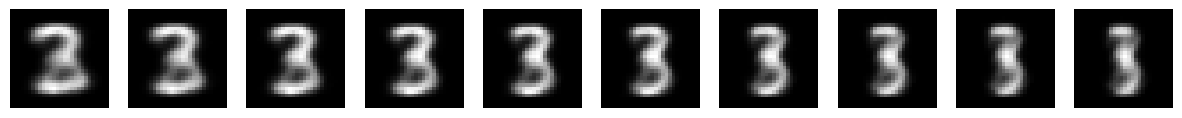

In [ ]:
def interpolate(model, z1, z2, n=10):
    # z1'den z2'ye doğru n adımda git
    ratios = np.linspace(0, 1, n)
    z_list = [(1-r)*z1 + r*z2 for r in ratios]
    z_tensor = torch.stack(z_list).to(device)

    model.eval()
    with torch.no_grad():
        samples = model.decoder(z_tensor).cpu().numpy()

    plt.figure(figsize=(15, 2))
    for i in range(n):
        plt.subplot(1, n, i+1)
        plt.imshow(samples[i].reshape(28, 28), cmap='gray')
        plt.axis('off')
    plt.show()

# Gizli uzaydan rastgele iki nokta seçelim (z1 ve z2)
z1 = torch.randn(latent_dim)
z2 = torch.randn(latent_dim)
interpolate(model, z1, z2)

## Gizli Uzayda İnterpolasyon (Rakamlar Arası Geçiş)
Gizli uzaydan rastgele iki nokta seçip aralarında doğrusal bir yol oluşturuyorum. Bu yol üzerindeki her noktayı decoder'a verip çıkan görüntülere bakıyorum. Noktalar rastgele seçildiği için her çalıştırmada farklı bir geçiş çıkıyor.

## Sonuç
Bu projede MNIST üzerinde 2 boyutlu gizli uzaya sahip bir VAE eğittim. 10 epoch sonunda ortalama kayıp 189.77'den 154.27'ye düştü.

Gizli uzay grafiğinde 1, 6, 2 ve 7 rakamları az çok ayrı bölgelerde toplanıyor, 0, 3, 4, 5, 8 ve 9 ise ortada iç içe geçiyor. Manifold grafiğinde komşu noktalar benzer rakamlar üretiyor. Yeniden oluşturulan görüntüler ve interpolasyon çıktıları bulanık, bazı rakamlar (4 → 9, 5 → 8 gibi) başka rakama dönüşüyor.

Bu çalışmada tek bir hiperparametre ayarı kullandım ve test seti ayırmadım. İleride CNN tabanlı bir encoder/decoder, daha fazla epoch ve Fashion-MNIST gibi başka veri setleri denenebilir.